# Unit 9: CNN Model Activity
This notebook runs the supplied exercise, *Convolutional Neural Networks (CNN) - Object Recognition*, which trains a small convolutional network on the CIFAR-10 images and predicts the class of single test images. I ran it in Google Colab with a T4 GPU (Runtime, then Change runtime type).

## Scope and corrections
I worked on a copy and kept the supplied text, code and model. Three changes let it run in current versions: `array_to_img` is now imported from `keras.utils`, the removed `model.predict_classes` is replaced by `np.argmax` over `model.predict`, and the cells run in order (the supplied file had run the prediction cell out of order). I also corrected one comment: the first training image is a frog, label 6, not an automobile. The model, its settings and the early stopping are unchanged.

After the supplied run I add my own checks: which epoch the final weights come from, how the errors are spread across the ten classes, the brief's task of changing the test image from 16 to 1 to 15, my chosen image (7), and how confident the model is when it is wrong.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 11 November 2026 at 14:27 UTC


## Part 1: the supplied exercise (three run fixes, one comment corrected)

![Screenshot%202021-02-04%20at%2010.30.29%20am.png](attachment:Screenshot%202021-02-04%20at%2010.30.29%20am.png)

# Convolutional Neural Networks (CNN) - Object Recognition

# Imports

In [2]:
from numpy.random import seed
seed(888)

#from tensorflow import set_random_seed
#set_random_seed(4112)
import tensorflow
tensorflow.random.set_seed(112)

In [3]:
import os
import numpy as np
import itertools

import tensorflow as tf
import keras
from keras.datasets import cifar10 # importing the dataset

from keras.models import Sequential       #to define model/ layers
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten

from sklearn.metrics import confusion_matrix

# To Explore the images
from IPython.display import display
# Corrected: array_to_img moved from keras.preprocessing.image to keras.utils
from keras.utils import array_to_img

from tensorflow.keras.utils import to_categorical

import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
import pandas as pd

We are using Tensorflow to power Keras

# Get the Dataset

CIFAR-10  is an established computer-vision dataset used for object recognition. It is a subset of the 80 million tiny images dataset and consists of 60,000 32x32 color images containing one of 10 object classes, with 6000 images per class. It was collected by Alex Krizhevsky, Vinod Nair, and Geoffrey Hinton.
The dataset is popularly used to train image classification models

![Screenshot%202021-02-05%20at%2012.47.25%20pm.png](attachment:Screenshot%202021-02-05%20at%2012.47.25%20pm.png)

In [5]:
# Getting the dataset as a Tuple

(x_train_all, y_train_all), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1657s 10us/step


# Constants

In [6]:
LABEL_NAMES = ['airplane', 'automobile','bird','cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Exploring the Data

Lets look at the first image in the dataset

In [7]:
x_train_all.shape

(50000, 32, 32, 3)

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]], shape=(32, 32, 3), dtype=uint8)
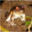

In [8]:
x_train_all[0]

In [9]:
x_train_all[0].shape

(32, 32, 3)

#### Using ipython to display the image

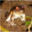

In [10]:
# To use the ipython display to view an image

pic = array_to_img(x_train_all[0])
display(pic)

#### Using Matplotlib to view the image

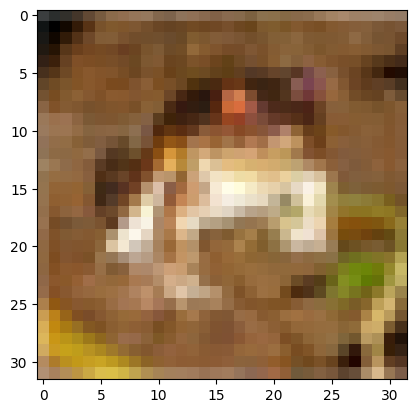

In [11]:
plt.imshow(x_train_all[0])


In [12]:
# To check the label
y_train_all.shape

(50000, 1)

In [13]:
# Corrected comment: the image above is a frog, so its label is 6 (LABEL_NAMES[6] is "frog")
# we have a 2 dimension numpy array; that is why we also include " [0] "

y_train_all[0][0]

np.uint8(6)

In [14]:
# Using the lable names to get the actual names of classes

LABEL_NAMES[y_train_all[0][0]]

'frog'

### The shape of the image
    * 32, 32 is the weight and the height
    * 3 is the number of channels (These are the number of colors): Red, Green & Blue (RGB)
    
 * x_train_all.shape  >>> (50000, 32, 32, 3)
     * this means we have 50,000 entries | then 32x32  weight and height| 3 colors (RGB)

In [15]:
x_train_all.shape

(50000, 32, 32, 3)

In [16]:
number_of_images, x, y, c = x_train_all.shape
print(f'Number of images = {number_of_images} \t| width = {x} \t| height = {y} \t| channels = {c}')

Number of images = 50000 	| width = 32 	| height = 32 	| channels = 3


In [17]:
x_test.shape

(10000, 32, 32, 3)

# Preprocess Data

#### * We need to preprocess our data so that it is easier to feed it to our neural network.


### Scalling both x_train and test


In [18]:
x_train_all =x_train_all / 255.0

In [19]:
x_test =  x_test / 255.0

In [20]:
y_test

array([[3],
       [8],
       [8],
       ...,
       [5],
       [1],
       [7]], shape=(10000, 1), dtype=uint8)

### Creating categorical encoding for the "y " data

In [21]:
# 10 >>> simply means we have 10 classes like we already know (creating the encoding for 10 classes)
y_cat_train_all = to_categorical(y_train_all,10)

In [22]:
# 10 >>> simply means we have 10 classes like we already know (creating the encoding for 10 classes)
y_cat_test = to_categorical(y_test,10)

In [23]:
y_cat_train_all

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(50000, 10))

# Creating the Validation dataset
![Screenshot%202021-02-05%20at%206.37.47%20pm.png](attachment:Screenshot%202021-02-05%20at%206.37.47%20pm.png)

For small data we usually go with:
    * 60% for Training
    * 20% Validation
    * 20% Testing
    
Only the final selected model gets to see the testing data. This helps us to ensure that we have close to real data in real-world when the model is deployed. Only our best model gets to see our testing dataset. Because it will give us a realistic impression of how our model will do in the real world
___

However, if the dataset is enormous.:
    * 1% for is used for validation
    * 1% for is used for testing

In [24]:
VALIDATION_SIZE = 10000

In [25]:
# VALIDATION_SIZE = 10,000 as defined above

x_val = x_train_all[:VALIDATION_SIZE]
y_val_cat = y_cat_train_all[:VALIDATION_SIZE]
x_val.shape

(10000, 32, 32, 3)

In [26]:
y_val_cat

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))

<b>NEXT:</b>
* We Create two NumPy arrays x_train and y_train that have the shape(40000, 3072) and (40000,1) respectively.
* They will contain the last 40000 values from x_train_all and y_train_all respectively

In [27]:
x_train = x_train_all[VALIDATION_SIZE:]
y_cat_train= y_cat_train_all[VALIDATION_SIZE:]

In [28]:
x_train.shape

(40000, 32, 32, 3)

In [29]:
y_cat_train

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(40000, 10))

 ![Screenshot%202021-02-15%20at%208.04.47%20pm.png](attachment:Screenshot%202021-02-15%20at%208.04.47%20pm.png)
 ## NOTE:
 <h4>* <em>FILTERS: </em>
    Typical values for the number of filters can be determined by the data set's complexity. So essentially the larger the images, the more variety and the more classes you're trying to classify then the more filters you should have.</h4>
   <h4> * Most times people typically pick filter based on powers of 2, for example, 32. However, if you have more complex data like road signs etc. you should be starting with a higher filter value</h4>
   <h4>The default STRIDE value is 1 x 1 pixel</h4>

# BUILDING THE MODEL

In [30]:
model = Sequential()

## ************* FIRST SET OF LAYERS *************************

# CONVOLUTIONAL LAYER
model.add(Conv2D(filters=32, kernel_size=(4,4),input_shape=(32, 32, 3), activation='relu',))
# POOLING LAYER
model.add(MaxPool2D(pool_size=(2, 2)))

## *************** SECOND SET OF LAYERS ***********************
#Since the shape of the data is 32 x 32 x 3 =3072 ...
#We need to deal with this more complex structure by adding yet another convolutional layer

# *************CONVOLUTIONAL LAYER
model.add(Conv2D(filters=32, kernel_size=(4,4),input_shape=(32, 32, 3), activation='relu',))
# POOLING LAYER
model.add(MaxPool2D(pool_size=(2, 2)))

# FLATTEN IMAGES FROM 32 x 32 x 3 =3072 BEFORE FINAL LAYER
model.add(Flatten())

# 256 NEURONS IN DENSE HIDDEN LAYER (YOU CAN CHANGE THIS NUMBER OF NEURONS)
model.add(Dense(256, activation='relu'))

# LAST LAYER IS THE CLASSIFIER, THUS 10 POSSIBLE CLASSES
model.add(Dense(10, activation='softmax'))


model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,610 (881.29 KB)

 Trainable params: 225,610 (881.29 KB)

 Non-trainable params: 0 (0.00 B)

### Adding Early stopping

In [32]:
from tensorflow.keras.callbacks import EarlyStopping

In [33]:
early_stop = EarlyStopping(monitor='val_loss',patience=2)

In [34]:
history = model.fit(x_train,y_cat_train,epochs=25,validation_data=(x_val,y_val_cat),callbacks=[early_stop])

Epoch 1/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.4224 - loss: 1.5904 - val_accuracy: 0.5082 - val_loss: 1.3419
Epoch 2/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5453 - loss: 1.2815 - val_accuracy: 0.5622 - val_loss: 1.2161
Epoch 3/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5995 - loss: 1.1406 - val_accuracy: 0.6002 - val_loss: 1.1376
Epoch 4/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6373 - loss: 1.0325 - val_accuracy: 0.6180 - val_loss: 1.1134
Epoch 5/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6714 - loss: 0.9437 - val_accuracy: 0.6310 - val_loss: 1.0997
Epoch 6/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6966 - loss: 0.8659 - val_accuracy: 0.6380 - val_loss: 1.1087
Epoch 7/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7247 - loss: 0.7912 - val_accuracy: 0.6455 - val_loss: 1.1111


In [35]:
model.history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [36]:
metrics = pd.DataFrame(model.history.history)

In [37]:
metrics

,accuracy,loss,val_accuracy,val_loss
0,0.422375,1.590428,0.5082,1.341911
1,0.545300,1.281517,0.5622,1.216123
2,0.599525,1.140641,0.6002,1.137625
3,0.637275,1.032508,0.6180,1.113375
4,0.671350,0.943743,0.6310,1.099669
5,0.696600,0.865916,0.6380,1.108689
6,0.724675,0.791203,0.6455,1.111140


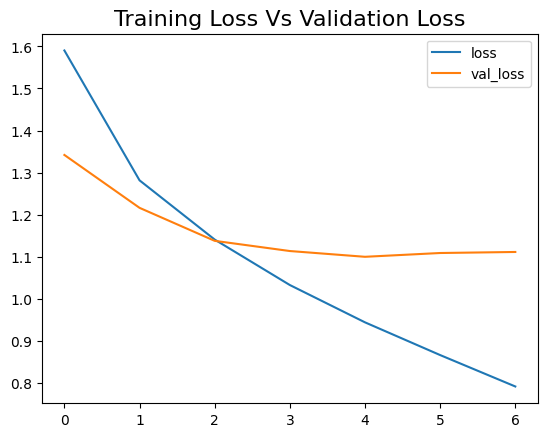

In [38]:
metrics[['loss', 'val_loss']].plot()
plt.title('Training Loss Vs Validation Loss', fontsize=16)
plt.show()

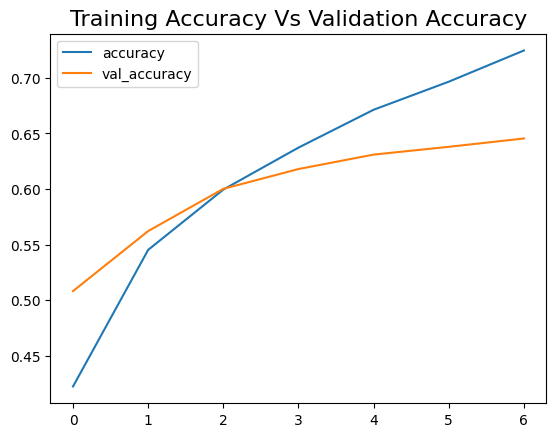

In [39]:
metrics[['accuracy', 'val_accuracy']].plot()
plt.title('Training Accuracy Vs Validation Accuracy', fontsize=16)
plt.show()

## Validating on Test Data

In [40]:
model.evaluate(x_test,y_cat_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6391 - loss: 1.1332


[1.133178949356079, 0.6391000151634216]

## Classification Report and Confusion Matrix

In [41]:
from sklearn.metrics import classification_report, confusion_matrix

In [42]:
#predictions = model.predict_classes(x_test)
predictions = np.argmax(model.predict(x_test), axis=-1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [43]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.75      0.68      0.71      1000
           1       0.79      0.71      0.75      1000
           2       0.53      0.52      0.53      1000
           3       0.42      0.55      0.47      1000
           4       0.61      0.53      0.57      1000
           5       0.52      0.56      0.54      1000
           6       0.66      0.77      0.71      1000
           7       0.72      0.66      0.69      1000
           8       0.81      0.70      0.75      1000
           9       0.71      0.71      0.71      1000

    accuracy                           0.64     10000
   macro avg       0.65      0.64      0.64     10000
weighted avg       0.65      0.64      0.64     10000



In [44]:
confusion_matrix(y_test,predictions)

array([[676,  26,  63,  48,  16,  16,  19,  20,  65,  51],
       [ 29, 712,  17,  24,   2,  22,  27,   6,  25, 136],
       [ 45,   3, 522, 107,  87,  76, 102,  30,  17,  11],
       [  8,   4,  72, 546,  59, 177,  80,  34,   7,  13],
       [ 16,   2,  94,  95, 530,  67,  96,  79,  17,   4],
       [  5,   3,  64, 233,  49, 565,  26,  45,   3,   7],
       [  4,   4,  54,  75,  37,  34, 770,  10,   6,   6],
       [ 10,   2,  44,  86,  70,  99,  11, 664,   3,  11],
       [ 84,  56,  24,  41,   9,  16,  18,   6, 698,  48],
       [ 19,  89,  25,  57,   4,  25,  22,  25,  26, 708]])

# Predicting on single image

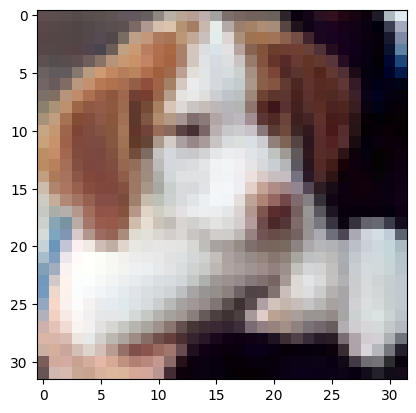

In [45]:
plt.imshow(x_test[16])

In [46]:
my_image = x_test[16]

In [47]:
# SHAPE --> (num_images,width,height,color_channels)
# Corrected: predict_classes was removed from Keras; take the most likely class instead
np.argmax(model.predict(my_image.reshape(1,32,32,3)), axis=-1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([5])

In [48]:
LABEL_NAMES[y_test[16][0]]

'dog'

## Part 2: my checks

### 1. Which epoch the final weights come from
The supplied early stopping watches the validation loss with a patience of 2 and does not restore the best weights, so the model keeps the weights from the last epoch it ran.

In [49]:
results = {}
hist = pd.DataFrame(history.history)
best = int(hist['val_loss'].idxmin())
last = len(hist) - 1
print(f"Epochs run: {len(hist)}")
print(f"Lowest validation loss at epoch {best + 1}: {hist.val_loss[best]:.4f} (validation accuracy {hist.val_accuracy[best]:.4f})")
print(f"Final epoch {last + 1}: validation loss {hist.val_loss[last]:.4f}, validation accuracy {hist.val_accuracy[last]:.4f}")
print(f"Final training accuracy {hist.accuracy[last]:.4f} against validation accuracy {hist.val_accuracy[last]:.4f}")
results['epochs_run'] = len(hist); results['best_epoch'] = best + 1
results['history'] = hist.round(4).to_dict(orient='list')

Epochs run: 7
Lowest validation loss at epoch 5: 1.0997 (validation accuracy 0.6310)
Final epoch 7: validation loss 1.1111, validation accuracy 0.6455
Final training accuracy 0.7247 against validation accuracy 0.6455


### 2. How the errors are spread across the ten classes
The supplied report lists classes by number. Here they are by name, with the most confused pairs.

In [50]:
test_loss, test_acc = model.evaluate(x_test, y_cat_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f} on {len(x_test)} images (test loss {test_loss:.4f})")
print(classification_report(y_test, predictions, target_names=LABEL_NAMES, digits=3))
rep = classification_report(y_test, predictions, target_names=LABEL_NAMES, output_dict=True)
recall = pd.Series({k: rep[k]['recall'] for k in LABEL_NAMES}).sort_values()
print('Recall from lowest to highest:'); print(recall.round(3).to_string())
cm = confusion_matrix(y_test, predictions)
pairs = [(LABEL_NAMES[i], LABEL_NAMES[j], int(cm[i, j])) for i in range(10) for j in range(10) if i != j]
pairs.sort(key=lambda p: -p[2])
print('\nMost common mistakes (true class -> predicted class: count of 1,000):')
for t, p, n in pairs[:5]: print(f"  {t} -> {p}: {n}")
results['test_accuracy'] = float(test_acc); results['test_loss'] = float(test_loss)
results['recall'] = recall.round(4).to_dict(); results['top_confusions'] = pairs[:5]

Test accuracy: 0.6391 on 10000 images (test loss 1.1332)
              precision    recall  f1-score   support

    airplane      0.754     0.676     0.713      1000
  automobile      0.790     0.712     0.749      1000
        bird      0.533     0.522     0.528      1000
         cat      0.416     0.546     0.472      1000
        deer      0.614     0.530     0.569      1000
         dog      0.515     0.565     0.539      1000
        frog      0.658     0.770     0.709      1000
       horse      0.723     0.664     0.692      1000
        ship      0.805     0.698     0.748      1000
       truck      0.712     0.708     0.710      1000

    accuracy                          0.639     10000
   macro avg      0.652     0.639     0.643     10000
weighted avg      0.652     0.639     0.643     10000

Recall from lowest to highest:
bird          0.522
deer          0.530
cat           0.546
dog           0.565
horse         0.664
airplane      0.676
ship          0.698
truck        

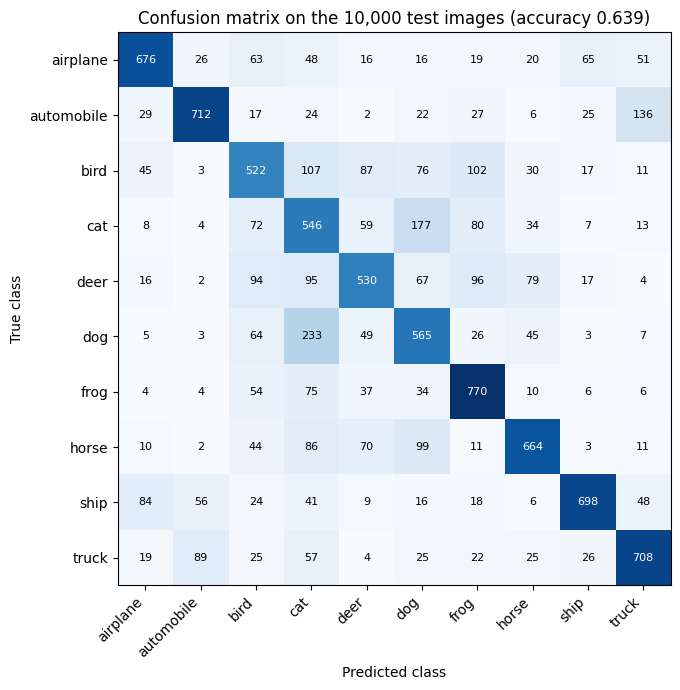

In [51]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10)); ax.set_xticklabels(LABEL_NAMES, rotation=45, ha='right')
ax.set_yticks(range(10)); ax.set_yticklabels(LABEL_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
ax.set_title(f'Confusion matrix on the 10,000 test images (accuracy {test_acc:.3f})')
plt.tight_layout(); plt.show()

### 3. The brief's task: test images 1 to 15, and the supplied 16
The brief asks me to change `x_test[16]` to a value of my choice from 1 to 15 and see whether the model predicts correctly. I check all of them, with the model's confidence in its answer.

In [52]:
idx = list(range(1, 17))
probs = model.predict(x_test[idx], verbose=0)
rows = []
for k, i in enumerate(idx):
    p = int(np.argmax(probs[k])); t = int(y_test[i][0])
    rows.append({'index': i, 'true': LABEL_NAMES[t], 'predicted': LABEL_NAMES[p],
                 'confidence': round(float(probs[k][p]), 3), 'correct': p == t})
table = pd.DataFrame(rows).set_index('index')
print(table.to_string())
print(f"\nCorrect for images 1 to 15: {int(table.loc[1:15, 'correct'].sum())} of 15")
results['images_1_to_16'] = rows

             true   predicted  confidence  correct
index                                             
1            ship  automobile       0.497    False
2            ship        ship       0.710     True
3        airplane    airplane       0.991     True
4            frog        deer       0.822    False
5            frog        frog       0.570     True
6      automobile  automobile       0.796     True
7            frog        frog       0.951     True
8             cat         cat       0.526     True
9      automobile  automobile       0.930     True
10       airplane        ship       0.379    False
11          truck       truck       0.944     True
12            dog         dog       0.780     True
13          horse       horse       0.963     True
14          truck       truck       0.858     True
15           ship        frog       0.953    False
16            dog         dog       0.933     True

Correct for images 1 to 15: 11 of 15


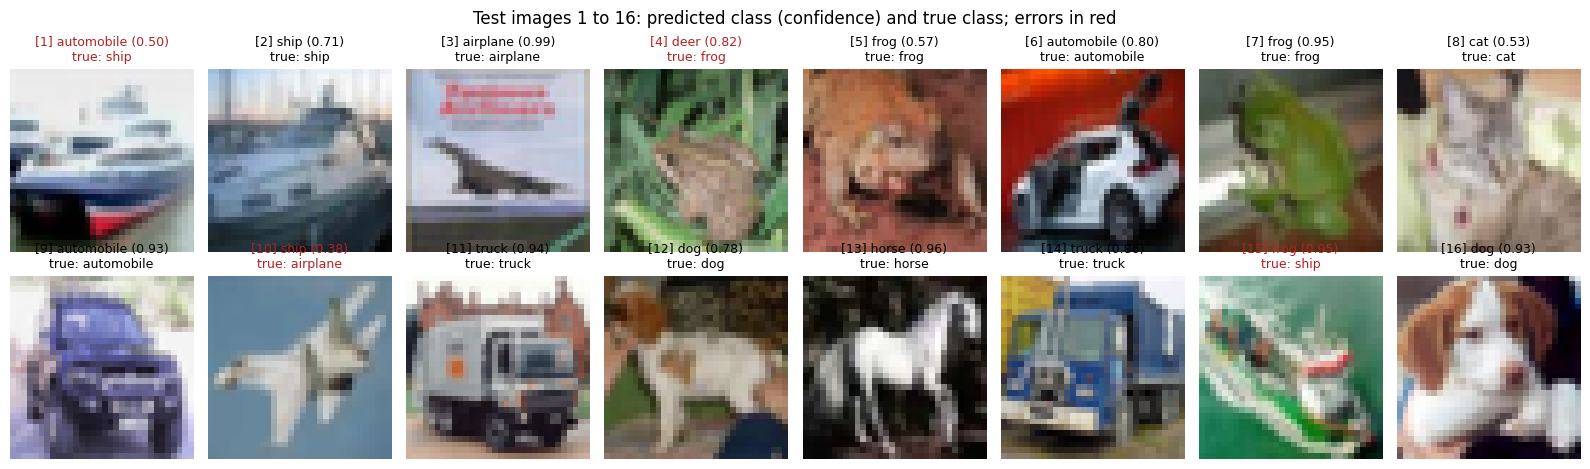

In [53]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for ax, (k, i) in zip(axes.ravel(), enumerate(idx)):
    r = rows[k]
    ax.imshow(x_test[i]); ax.axis('off')
    ax.set_title(f"[{i}] {r['predicted']} ({r['confidence']:.2f})\ntrue: {r['true']}", fontsize=9,
                 color='black' if r['correct'] else 'firebrick')
fig.suptitle('Test images 1 to 16: predicted class (confidence) and true class; errors in red')
plt.tight_layout(); plt.show()

### 4. My chosen image
I chose image 7 before seeing any results.

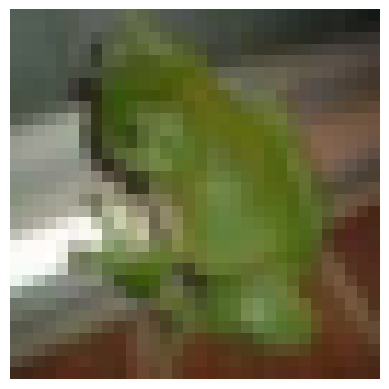

True class: frog
Predicted class: frog | correct: True
Three most likely classes: [('frog', 0.951), ('bird', 0.029), ('cat', 0.017)]


In [54]:
MY_CHOICE = 7   # chosen before the run; change the number to test another image
plt.imshow(x_test[MY_CHOICE]); plt.axis('off'); plt.show()
p_my = model.predict(x_test[MY_CHOICE].reshape(1, 32, 32, 3), verbose=0)[0]
top3 = np.argsort(p_my)[::-1][:3]
print('True class:', LABEL_NAMES[y_test[MY_CHOICE][0]])
print('Predicted class:', LABEL_NAMES[top3[0]], '| correct:', top3[0] == y_test[MY_CHOICE][0])
print('Three most likely classes:', [(LABEL_NAMES[c], round(float(p_my[c]), 3)) for c in top3])
results['my_choice'] = {'index': MY_CHOICE, 'true': LABEL_NAMES[y_test[MY_CHOICE][0]],
                        'top3': [(LABEL_NAMES[c], float(p_my[c])) for c in top3]}

### 5. How confident the model is when it is wrong
A wrong answer given with high confidence is the kind of error a user is least likely to question.

In [55]:
all_probs = model.predict(x_test, verbose=0)
conf = all_probs.max(axis=1)
wrong = predictions != y_test.ravel()
print(f"Wrong predictions: {int(wrong.sum())} of {len(wrong)}")
for cut in (0.5, 0.8, 0.9):
    print(f"  wrong with confidence of {cut} or more: {int((wrong & (conf >= cut)).sum())}")
print(f"Average confidence: right {conf[~wrong].mean():.3f}, wrong {conf[wrong].mean():.3f}")
results['wrong_total'] = int(wrong.sum())
results['wrong_conf_ge_0_9'] = int((wrong & (conf >= 0.9)).sum())
results['mean_conf_right'] = float(conf[~wrong].mean()); results['mean_conf_wrong'] = float(conf[wrong].mean())

Wrong predictions: 3609 of 10000
  wrong with confidence of 0.5 or more: 2361
  wrong with confidence of 0.8 or more: 673
  wrong with confidence of 0.9 or more: 330
Average confidence: right 0.805, wrong 0.601


### 6. Summary of results

In [56]:
import json, sys, platform
results['versions'] = {'python': platform.python_version(), 'tensorflow': tf.__version__, 'keras': keras.__version__}
results['gpu'] = [d.name for d in tf.config.list_physical_devices('GPU')]
print(json.dumps(results, indent=1, default=str))

{
 "epochs_run": 7,
 "best_epoch": 5,
 "history": {
  "accuracy": [
   0.4224,
   0.5453,
   0.5995,
   0.6373,
   0.6714,
   0.6966,
   0.7247
  ],
  "loss": [
   1.5904,
   1.2815,
   1.1406,
   1.0325,
   0.9437,
   0.8659,
   0.7912
  ],
  "val_accuracy": [
   0.5082,
   0.5622,
   0.6002,
   0.618,
   0.631,
   0.638,
   0.6455
  ],
  "val_loss": [
   1.3419,
   1.2161,
   1.1376,
   1.1134,
   1.0997,
   1.1087,
   1.1111
  ]
 },
 "test_accuracy": 0.6391000151634216,
 "test_loss": 1.133178949356079,
 "recall": {
  "bird": 0.522,
  "deer": 0.53,
  "cat": 0.546,
  "dog": 0.565,
  "horse": 0.664,
  "airplane": 0.676,
  "ship": 0.698,
  "truck": 0.708,
  "automobile": 0.712,
  "frog": 0.77
 },
 "top_confusions": [
  [
   "dog",
   "cat",
   233
  ],
  [
   "cat",
   "dog",
   177
  ],
  [
   "automobile",
   "truck",
   136
  ],
  [
   "bird",
   "cat",
   107
  ],
  [
   "bird",
   "frog",
   102
  ]
 ],
 "images_1_to_16": [
  {
   "index": 1,
   "true": "ship",
   "predicted": "aut